## Setup

In [1]:
%pip install --upgrade pip

  Obtaining dependency information for pip from https://files.pythonhosted.org/packages/47/6a/453160888fab7c6a432a6e25f8afe6256d0d9f2cbd25971021da6491d899/pip-23.3.1-py3-none-any.whl.metadata
  Using cached pip-23.3.1-py3-none-any.whl.metadata (3.5 kB)
Using cached pip-23.3.1-py3-none-any.whl (2.1 MB)
  Attempting uninstall: pip
    Found existing installation: pip 23.2.1
    Uninstalling pip-23.2.1:
      Successfully uninstalled pip-23.2.1
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade -q botocore boto3

Note: you may need to restart the kernel to use updated packages.


In [3]:
import boto3

In [5]:
sess = boto3.Session(profile_name='')
bedrock = sess.client('bedrock', 'us-west-2')
response = bedrock.list_foundation_models()
print(response.get('modelSummaries')) 

[{'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-tg1-large', 'modelId': 'amazon.titan-tg1-large', 'modelName': 'Titan Text Large', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['TEXT'], 'responseStreamingSupported': True, 'customizationsSupported': ['FINE_TUNING'], 'inferenceTypesSupported': ['ON_DEMAND']}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-embed-g1-text-02', 'modelId': 'amazon.titan-embed-g1-text-02', 'modelName': 'Titan Text Embeddings v2', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['EMBEDDING'], 'customizationsSupported': [], 'inferenceTypesSupported': ['ON_DEMAND']}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-text-lite-v1', 'modelId': 'amazon.titan-text-lite-v1', 'modelName': 'Titan Text G1 - Lite', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['TEXT'], 'responseStreamingSupported': True, 'customizations

In [6]:
bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [7]:
s3 = sess.resource('s3')

In [8]:
def initialise_bedrock():
    global bedrock
    if bedrock is None:
        sess = boto3.Session(profile_name='')
        bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [9]:
import boto3
def initialise_s3():
    global s3
    if s3 is None:
        sess = boto3.Session(profile_name='')
        s3 = sess.resource('s3')

## Get products into dynamodb

In [ ]:
!aws s3 cp --profile  s3://YOUR_BUCKET_NAME/FlipkartProd/flipkart_com-ecommerce_sample.csv .

In [ ]:
%pip install --quiet tqdm

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import csv
import json
from decimal import Decimal
from tqdm import tqdm
import boto3
from boto3.dynamodb.types import TypeSerializer

In [ ]:
#Initialize the DynamoDB resource
dynamodb = sess.resource('dynamodb')

In [ ]:
def is_json(value):
    try:
        json.loads(value)
        return True
    except:
        return False

In [ ]:
def extract_lists(row, column):
    list_string = row.get(column, "").strip('[]').strip('"')
    if column == "product_category_tree":
        return [cat.strip() for cat in list_string.split(">>")]
    else:
        return [url.strip() for url in list_string.split(",")]

In [ ]:
def simplify_product_specification(product_spec_json):
    simplified_json = {}
    for item in product_spec_json.get('product_specification', []):
        key = item.get('key', None)
        value = item.get('value', None)
        if key and value:
            simplified_json[key] = value
    return simplified_json

In [ ]:


serializer = TypeSerializer()

def convert_to_dynamodb_format_enhanced(value, column=None):
    if column == "product_specifications":
        try:
            # Replace "=>" with ":" to make it a valid Python object
            corrected_value = value.replace("=>", ":")
            # Use ast.literal_eval to convert the string to a Python object
            python_object = json.loads(corrected_value)
            # Serialize the Python object to DynamoDB format
            return serializer.serialize(simplify_product_specification(python_object))
        except Exception as e:
            # If conversion fails, store it as a string
            return {"S": value.strip('"')}
    if column and 'price' in column:
        # Convert the price to a float
        if value.strip():
            return serializer.serialize(Decimal(str(value)))
        else:
            return {"NULL": True}
    else:
        # Serialize other columns using the TypeSerializer
        return serializer.serialize(value.strip('"'))

In [ ]:
# Function to assign parent IDs to the category items in the adjacency list
def assign_parent_ids(adjacency_list_items):
    parent_child_dict = {}
    
    for item in adjacency_list_items:
        category_id = item['PutRequest']['Item']['category_id']['S']
        parent_id = item['PutRequest']['Item']['parent_id']['S']
        
        if parent_id == "TBD":
            parent_id = parent_child_dict.get(category_id, "null")
            item['PutRequest']['Item']['parent_id']['S'] = parent_id
            
# Updated function to convert CSV to DynamoDB compatible JSON using Adjacency List for category trees
def csv_to_dynamodb_json_with_adjacency_list(csv_file_path, json_file_path):
    parent_child_dict = {}  # To store parent-child relationships
    dynamodb_items = []  # For storing product items
    adjacency_list_items = []  # For storing category items
    
    with open(csv_file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        
        for row in csv_reader:
            dynamodb_item = {}
            categories = extract_lists(row, "product_category_tree")
            images = extract_lists(row, "image")
            
            # Update parent-child relationships
            for i, category in enumerate(categories):
                parent = categories[i - 1] if i > 0 else "null"
                parent_child_dict[category] = parent
            
            for column, value in row.items():
                if column == "product_category_tree":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(cat) 
                                                   for cat in categories]}
                elif column == "image":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(img) for img in images]}
                elif column == "uniq_id":
                    dynamodb_item['id'] = convert_to_dynamodb_format_enhanced(value, column)
                else:
                    dynamodb_item[column] = convert_to_dynamodb_format_enhanced(value, column)
                    
            dynamodb_items.append({"PutRequest": {"Item": dynamodb_item}})
    
    # Generate the adjacency list items
    for category, parent in parent_child_dict.items():
        adjacency_list_items.append({
            "PutRequest": {
                "Item": {
                    "category_id": {"S": category},
                    "parent_id": {"S": parent}
                }
            }
        })
    
    # Assign parent IDs
    assign_parent_ids(adjacency_list_items)
    
    with open(json_file_path, 'w') as json_file:
        json.dump({
            "ProductTable": {"Items": dynamodb_items},
            "CategoryTable": {"Items": adjacency_list_items}
        }, json_file, indent=4)

In [ ]:
csv_to_dynamodb_json_with_adjacency_list("flipkart_com-ecommerce_sample.csv", "flipkart_com-ecommerce_sample.json")

In [ ]:
 

# Create 'ProductTable'
product_table = dynamodb.create_table(
    TableName='ProductTable',
    KeySchema=[
        {'AttributeName': 'id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Create 'CategoryTable'
category_table = dynamodb.create_table(
    TableName='CategoryTable',
    KeySchema=[
        {'AttributeName': 'category_id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'category_id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Wait for tables to be created
product_table.meta.client.get_waiter('table_exists').wait(TableName='ProductTable')
category_table.meta.client.get_waiter('table_exists').wait(TableName='CategoryTable')


In [ ]:

def batch_write_chunks(table_name, table_data):
    dynamodb = sess.client('dynamodb')
    chunk_size = 25  # DynamoDB batch write limit
    
    # Extract the list of items wrapped in 'PutRequest'
    items_list = table_data.get('Items', [])
    
    for i in tqdm(range(0, 2000 if table_name=='ProductTable' else (int(len(items_list))), chunk_size)):
        chunk = items_list[i:i + chunk_size]
        request = {
            table_name: chunk
        }
        dynamodb.batch_write_item(RequestItems=request)

# Load JSON data from the file
with open('flipkart_com-ecommerce_sample.json', 'r') as f:
    data = json.load(f)

# Batch write items to 'ProductTable'
if 'ProductTable' in data:
    batch_write_chunks('ProductTable', data['ProductTable'])

# Batch write items to 'CategoryTable'
if 'CategoryTable' in data:
    batch_write_chunks('CategoryTable', data['CategoryTable'])


100%|██████████| 362/362 [01:25<00:00,  4.25it/s]


## Set up Model

In [10]:
%pip install -U -q sagemaker transformers==4.26.0

Note: you may need to restart the kernel to use updated packages.


In [11]:
import sagemaker
import boto3
sagesess = sagemaker.Session(boto_session=sess)

sagemaker_session_bucket=None
if sagemaker_session_bucket is None and sagesess is not None:
    sagemaker_session_bucket = sagesess.default_bucket()

sagesess = sagemaker.Session(boto_session=sess,default_bucket=sagemaker_session_bucket)

print(f"sagemaker bucket: {sagesess.default_bucket()}")
print(f"sagemaker session region: {sagesess.boto_region_name}")

sagemaker.config INFO - Not applying SDK defaults from location: /Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/unabened/Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/unabened/Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Library/Application Support/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /Users/unabened/Library/Application Support/sagemaker/config.yaml
sagemaker bucket: sagemaker-us-west-2-ACCOUNT_ID
sagemaker session region: us-west-2


In [12]:
!mkdir code

mkdir: code: File exists


In [13]:
%%writefile code/inference.py
import io
import json
import logging
import sys
from typing import Dict, Tuple
import torch
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
import numpy as np

logger = logging.getLogger(__name__)
logger.setLevel(logging.DEBUG)
logger.addHandler(logging.StreamHandler(sys.stdout))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def accurate_token_count(text: str, processor: CLIPProcessor) -> int:
    return len(processor.tokenizer(text).input_ids)

def chunk_text(text: str, processor: CLIPProcessor, max_tokens: int = 77) -> list:
    words = text.split()
    chunks, chunk, tokens = [], [], 0
    
    for word in words:
        new_token_count = accurate_token_count(word, processor)
        if tokens + new_token_count > max_tokens:
            chunks.append(" ".join(chunk))
            chunk = [word]
            tokens = new_token_count
        else:
            chunk.append(word)
            tokens += new_token_count
            
    if chunk:
        chunks.append(" ".join(chunk))
        
    return chunks

def model_fn(model_dir: str) -> Tuple[CLIPModel, CLIPProcessor]:
    model = CLIPModel.from_pretrained(model_dir).to(device)
    processor = CLIPProcessor.from_pretrained(model_dir)
    return model, processor

def input_fn(request_body, request_content_type):
    assert request_content_type in ("application/json", "application/x-image"), f"{request_content_type} is an unknown type."
    
    content_type_map = {
        "application/json": lambda x: json.loads(x)["inputs"],
        "application/x-image": lambda x: Image.open(io.BytesIO(x))
    }
    
    return request_content_type, content_type_map[request_content_type](request_body)

def predict_fn(request_content_type_and_input_object, model_and_processor):
    model, processor = model_and_processor
    request_content_type, input_object = request_content_type_and_input_object
    
    def chunk_and_process_text(text):
        text_chunks = chunk_text(text, processor)
        features_sum, count = None, 0
        
        for text_chunk in text_chunks:
            inputs = processor(text=text_chunk, padding=True, return_tensors="pt").to(device)
            try:
                features = model.get_text_features(**inputs)
                if features_sum is None:
                    features_sum = torch.zeros_like(features).to(device)
                features_sum += features
                count += 1
            except RuntimeError as e:
                logger.error(f"Text chunk '{text_chunk}' of length {len(text_chunk)} caused an error: {e}")

        return (features_sum / count).detach()
        
    input_processors = {
        "application/x-image": lambda x: processor(images=x, padding=True, return_tensors="pt").to(device),
        "application/json": lambda x: chunk_and_process_text(x)
    }
    
    feature_getters = {
        "application/x-image": lambda x: model.get_image_features(**x),
        "application/json": lambda x: x 
    }
    
    inputs = input_processors[request_content_type](input_object)
    return feature_getters[request_content_type](inputs)

Overwriting code/inference.py


In [14]:
%%writefile code/requirements.txt
transformers==4.26.0
langchain

Overwriting code/requirements.txt


In [16]:
repository = "openai/clip-vit-large-patch14"
model_id=repository.split("/")[-1]
s3_location=f"s3://{sagesess.default_bucket()}/custom_inference/{model_id}/model.tar.gz"

In [ ]:
%conda install -y -c conda-forge git-lfs
!git lfs install

Retrieving notices: ...working... done
Solving environment: done


==> WARNING: A newer version of conda exists. <==
  current version: 23.3.1
  latest version: 23.9.0

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize the number of packages updated during conda update use

     conda install conda=23.9.0



## Package Plan ##

  environment location: /Users/unabened/vs/.conda

  added / updated specs:
    - git-lfs


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    git-lfs-3.4.0              |       hce30654_0         3.6 MB  conda-forge
    ------------------------------------------------------------
                                           Total:         3.6 MB

The following NEW packages will be INSTALLED:

  git-lfs            conda-forge/osx-arm64::git-lfs-3.4.0-hce30654_0 



                                                              

In [ ]:
!git clone https://huggingface.co/$repository

Cloning into 'clip-vit-large-patch14'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 45 (delta 0), reused 0 (delta 0), pack-reused 44
Unpacking objects: 100% (45/45), 1.08 MiB | 5.17 MiB/s, done.
Filtering content: 100% (4/4), 6.37 GiB | 6.58 MiB/s, done.


In [ ]:
!cp -r code/ $model_id/code/

In [ ]:
%cd $model_id
!tar zcvf model.tar.gz *

/Users/unabened/vs/clip-vit-large-patch14
a README.md
a code
a code/requirements.txt
a code/inference.py
a config.json
a flax_model.msgpack
a merges.txt
a model.safetensors
a preprocessor_config.json
a pytorch_model.bin
a special_tokens_map.json
a tf_model.h5
a tokenizer.json
a tokenizer_config.json
a vocab.json


In [ ]:
!aws s3 cp --profile  model.tar.gz $s3_location

upload: ./model.tar.gz to s3://sagemaker-us-west-2-ACCOUNT_ID/custom_inference/clip-vit-large-patch14/model.tar.gz


In [18]:
from sagemaker.huggingface.model import HuggingFaceModel

# create Hugging Face Model Class
huggingface_model = HuggingFaceModel(
    model_data=s3_location,       # path to your model and script
    role="arn:aws:iam::ACCOUNT_ID:role/service-role/AmazonSageMaker-ExecutionRole-EXAMPLE",
    transformers_version="4.26.0",  # transformers version used
    pytorch_version="1.13.1",        # pytorch version used
    py_version='py39', # python version used
    sagemaker_session = sagesess
)

# deploy the endpoint endpoint
clip_model = huggingface_model.deploy(
    initial_instance_count=1,
    instance_type="ml.g4dn.xlarge",
    endpoint_name="clip-model",
    )

-------------!

In [ ]:
def initialise_clip_model():
    global clip_model
    if clip_model is None:
        sess = boto3.Session(profile_name='')
        sagesess = sagemaker.Session(boto_session=sess)
        clip_model = sagemaker.predictor.Predictor(endpoint_name="clip-model", sagemaker_session=sagesess)
        

## Get records

## Set up product desc generation

In [14]:
dynamodb = sess.resource('dynamodb')
table = dynamodb.Table('ProductTable')

lastEvaluatedKey = None
items = [] # Result Array

while True:
    if lastEvaluatedKey == None:
        response = table.scan() 
    else:
        response = table.scan(
        ExclusiveStartKey=lastEvaluatedKey
    )

    items.extend(response['Items'])

    if 'LastEvaluatedKey' in response:
        lastEvaluatedKey = response['LastEvaluatedKey']
    else:
        break

print(len(items))

2000


## Put images in S3 to avoid overloading original server

In [ ]:
%%bash

tablename='ProductTable'
lastevalkey=''
profile=''
> urls.txt

while : ; do
    if [[ -z $lastevalkey ]]; then
        response=$(aws dynamodb scan --profile $profile --table-name $tablename --projection-expression "image" --output json)
    else
        response=$(aws dynamodb scan --profile $profile--table-name $tablename --projection-expression "image" --exclusive-start-key $lastevalkey --output json)
    fi
    
    echo "$response" | jq -r '.Items[] | .image[]' >> urls.txt
    
    lastevalkey=$(echo "$response" | jq -r '.LastEvaluatedKey')
    if [[ $lastevalkey == null ]]; then
        break
    fi
done


In [ ]:
import json
import boto3
from urllib.parse import urlparse
import requests

# AWS Configuration
s3Session = boto3.Session(profile_name='')
s3 = s3Session.client('s3')
bucket_name = "flip-kart-images-rasripa-2023"

def upload_to_s3(url):
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    response = requests.get(url, stream=True)
    if response.status_code == 200:
        s3.upload_fileobj(response.raw, bucket_name, s3_path)
        print(f'Successfully uploaded {url} to s3://{bucket_name}/{s3_path}')
    else:
        print(f'Failed to retrieve {url}. HTTP Status Code: {response.status_code}')

def read_and_upload(file_path):
    accumulated_lines = ""
    with open(file_path, 'r') as file:
        for line in file:
            accumulated_lines += line.strip()
            try:
                items = json.loads(accumulated_lines)
                for item in items:
                    url = item.get('S', '')
                    if url:
                        upload_to_s3(url)
                # Clear accumulated lines if successful
                accumulated_lines = ""
            except json.JSONDecodeError:
                # Accumulate lines until a complete JSON array is formed
                continue

# Run the function
read_and_upload('urls.txt')


## Prompt GEN

In [15]:
from decimal import Decimal
from typing import Union, Dict, Any

def json_to_dict(json_input: Union[Dict[str, Any], str]) -> Dict[str, Any]:
    if isinstance(json_input, dict):
        return json_input
    elif isinstance(json_input, str):
        try:
            return json.loads(json_input.replace("=>", ":"))
        except json.JSONDecodeError:
            return {}
    else:
        return {}

def format_decimal(decimal_value: Union[Decimal, str, int]) -> str:
    return str(decimal_value)

def array_to_string(array: list) -> str:
    return ' > '.join(array)

def generate_prompt(product_data: Dict[str, Any]) -> str:
    description = product_data.get('description', '')
    discounted_price = format_decimal(product_data.get('discounted_price', ''))
    retail_price = format_decimal(product_data.get('retail_price', ''))
    product_name = product_data.get('product_name', '')
    product_category_tree = array_to_string(product_data.get('product_category_tree', []))
    product_specifications = json_to_dict(product_data.get('product_specifications', {}))

    template = (
        f"Given the following product details:\n"
        f"- Product ID: {product_data.get('id', '')}\n"
        f"- Brand: {product_data.get('brand', '')}\n"
        f"- Original Description: {description}\n"
        f"- Discounted Price: {discounted_price}\n"
        f"- Retail Price: {retail_price}\n"
        f"- Product Name: {product_name}\n"
        f"- Product Category: {product_category_tree}\n"
        f"- Product Specifications: {product_specifications.get('product_specification', '')}\n\n"
        f"Please generate an enhanced product description that incorporates all the above elements while ensuring "
        f"high-quality language and factual coherence. Make the description rich in relevant details "
        f"and present it in a format that includes:\n"
        f"- A compelling opening sentence\n"
        f"- Key features\n"
        f"- Benefits\n"
        f"- Usage instructions\n"
        f"- Pricing information\n\n"
    )
    return template


test = generate_prompt(items[13]) 


In [16]:
%pip install backoff

Note: you may need to restart the kernel to use updated packages.


In [17]:
import backoff
import json

def backoff_hdlr(details):
    """Handler from https://pypi.org/project/backoff/"""
    print(
        "Backing off {wait:0.1f} seconds after {tries} tries "
        "calling function {target} with kwargs "
        "{kwargs}".format(**details)
    )

In [18]:
from botocore.exceptions import ClientError
import random
import json

@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def generate_description(product_data: dict) -> str:
    generated_description = product_data.get('generated_description')
    if generated_description and 'Sorry' not in generated_description and len(generated_description) > 0:
        return generated_description
    prompt = generate_prompt(product_data)
    claude_prompt = f"\n\nHuman:{prompt}\n\nAssistant:"
    body = json.dumps({"prompt": claude_prompt,"max_tokens_to_sample":2000,
                       "temperature":0,"top_p":1,"stop_sequences": ["\n\nHuman:"],"top_k": 250})
    modelId = 'anthropic.claude-v2'
    accept = 'application/json'
    contentType = 'application/json'
    response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept,
                                    contentType=contentType)
    response_body = json.loads(response.get('body').read())
    if 'Sorry' in response_body.get('completion'):
        print(f'No description found for product:{product_data["description"]}')
        return ''
    #remove first line from response using \n
    return ' '.join(response_body.get('completion').split('\n',2)[2:])

In [19]:
print(generate_description(items[450]))

Add regal flair to your traditional outfits with the Vidhya Kangan Brass Jewel Set. This exquisite jewelry set by Vidhya Kangan features a beautifully crafted necklace and pair of matching earrings made from premium brass. 

The necklace showcases an intricate floral motif pendant flanked by gleaming beads and chains. Complementing it are a gorgeous pair of brass jhumka earrings that make a striking statement. These lightweight jewels are easy to wear and perfect for both everyday and festive occasions. 

Crafted using specialized metalwork techniques, the Vidhya Kangan Brass Jewel Set lends an authentic ethnic vibe to your look. The brass construction ensures durability and long-lasting shine. 

Valued at Rs. 1600, you can now buy this jewelry set for just Rs. 800 on Flipkart. Grab this deal to get 50% off on a high-quality product with a 30-day replacement guarantee. Order now and get free shipping plus cash on delivery for a completely risk-free purchase.

Elevate your style afforda

## Set up content retrieval

In [20]:
def get_id(product_data: dict) -> str:
    return product_data.get('id', '')

In [21]:
def get_image_url_list(product_data: dict) -> list:
    return product_data.get('image', [])

## Set up embedding retrieval

In [22]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [23]:
from PIL import Image
from io import BytesIO

def image_to_byte_array(image: Image.Image) -> bytearray:
    byte_io = BytesIO()
    image.save(byte_io, format='WEBP')
    return byte_io.getvalue()

In [24]:
import requests
from io import BytesIO
from PIL import Image
import json
import boto3
from urllib.parse import urlparse
import requests
from botocore.exceptions import ClientError




def fetch_image(url):
    bucket_name = "flip-kart-images-rasripa-2023"
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    obj = s3.Object(bucket_name, s3_path)
    try:
        return BytesIO(obj.get()['Body'].read()),True
    except Exception as e:
        return None,False


In [25]:
from sagemaker.deserializers import JSONDeserializer
from sagemaker.serializers import IdentitySerializer, JSONSerializer
import numpy as np

In [26]:
def fetch_or_byte(image_info):
    return bytearray(requests.get(image_info).content) if isinstance(image_info, str) else image_info

In [27]:
from botocore.exceptions import ReadTimeoutError
from typing import overload

@backoff.on_exception(
        backoff.expo,
        (ClientError, ReadTimeoutError ),
        max_time=random.randint(1000, 5000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ClientError' not in str(e) and 'ReadTimeoutError' not in str(e) and 'InternalServerException' not in str(e)
    ) 
def get_image_embedding(image_info, clip_model):
    clip_model.serializer = IdentitySerializer(content_type="application/x-image")
    clip_model.deserializer = JSONDeserializer()
    #clip_model.accept = 'application/json'
    return  clip_model.predict(
        data=image_info
    )

In [ ]:
get_image_embedding(fetch_image('http://img5a.flixcart.com/image/shoe/z/j/y/red-pepper-black-flash-yellow-asics-12-original-imaegah8pts8xab9.jpeg')[0], clip_model)

In [29]:
fetch_image('http://img5a.flixcart.com/image/dress/x/w/s/39327-yepme-s-1100x1360-imadz7q2hvdmkb76.jpeg')[1]

False

In [30]:
@backoff.on_exception(
        backoff.expo,
        (ClientError, ReadTimeoutError ),
        max_time=random.randint(1000, 5000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ClientError' not in str(e) and 'ReadTimeoutError' not in str(e) and 'InternalServerException' not in str(e)
    ) 
def get_text_embedding(text, clip_model):
    clip_model.serializer = JSONSerializer()
    clip_model.deserializer = JSONDeserializer()
    #clip_model.accept = 'application/json'
    return clip_model.predict({
        "inputs":
            text
        
    })

## Image Captioning

## Create and populate vector stores

In [31]:
%pip install --upgrade faiss-cpu --quiet

Note: you may need to restart the kernel to use updated packages.


In [32]:
import faiss

d = 768 
quantizer = faiss.IndexFlatL2(d)
try:
    text_index = faiss.read_index("text.index")
    print("text_index loaded")
    print(text_index.ntotal)
except Exception as e:
    text_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("text_index created")

text_index created


In [33]:
try:
    image_index = faiss.read_index("image.index")
    print("image index loaded")
    print(image_index.ntotal)
except Exception as e:
    image_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("image index created")

image index created


In [ ]:
'''text_index = faiss.IndexIVFFlat(quantizer, d, 10)
image_index = faiss.IndexIVFFlat(quantizer, d, 10)'''

In [34]:
def normalise_embedding(embedding):
    return embedding / np.linalg.norm(embedding)

In [35]:
import re
import unicodedata

def clean_and_prepare_text(text):
    # Normalize extra whitespace to single space
    text = re.sub(r'\s+', ' ', text).strip()
    
    # Remove special characters
    text = re.sub(r'[^\w\s]', '', text)
    
    # Unicode normalization
    text = unicodedata.normalize('NFKD', text)
    
    # Lowercasing
    text = text.lower()
    
    #text = text[:320]

    return text


In [36]:
def split_data(data, num_splits):
    avg = len(data) // num_splits
    out = []
    last = 0.0

    while last < len(data):
        out.append(data[int(last):int(last + avg)])
        last += avg

    return out


In [37]:
def process_item(item):
    return get_id(item), get_image_url_list(item), generate_description(item)

In [38]:
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import numpy as np
import requests
from requests.exceptions import ConnectionError,ReadTimeout
@backoff.on_exception(
        backoff.expo,
        (ConnectionError, ReadTimeout),
        max_time= random.randint(1000, 5000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ConnectionError' not in str(e) and 'ReadTimeout' not in str(e)
    )
def fetch_images(image_urls):
    with ThreadPoolExecutor() as executor:
        responses = list(executor.map(requests.get, image_urls))
    return responses

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import sys

def process_chunk_of_items(items_chunk):
    
    initialise_clip_model()
    initialise_bedrock()
    initialise_s3()
    local_image_training_embeddings = []
    local_text_training_embeddings = []
    
    for item in tqdm(items_chunk):
        item_id, image_url_list, description = process_item(item)
        image_embeddings = []
        sanitised_description = clean_and_prepare_text(description)        
        
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                image_embedding = np.array(get_image_embedding(image_content, clip_model))
                image_embeddings.append(image_embedding)
            except Exception as e:
                pass
        
        if len(image_embeddings) == 0:
            continue
        
        
        text_embedding = np.array(get_text_embedding(sanitised_description, clip_model))
        local_text_training_embeddings.append(np.ascontiguousarray(normalise_embedding(text_embedding)))
        local_image_training_embeddings.extend(image_embeddings)
    
    return local_image_training_embeddings, local_text_training_embeddings


NUM_THREADS = 100
items_chunks = split_data(items[:int(len(items)*0.8)], NUM_THREADS)

global_image_training_embeddings = []
global_text_training_embeddings = []

with ThreadPoolExecutor(max_workers=NUM_THREADS) as executor:
    futures = [executor.submit(process_chunk_of_items, chunk) for chunk in items_chunks]

for future in tqdm(futures):
    local_image_training_embeddings, local_text_training_embeddings = future.result()
    global_image_training_embeddings.extend(local_image_training_embeddings)
    global_text_training_embeddings.extend(local_text_training_embeddings)


In [40]:
len(global_image_training_embeddings)

5827

In [41]:
image_training_data = np.vstack(global_image_training_embeddings).astype('float32')
text_training_data = np.vstack(global_text_training_embeddings).astype('float32')

image_index.train(np.ascontiguousarray(image_training_data))
text_index.train(np.ascontiguousarray(text_training_data))

In [42]:
print("Training image data shape:", image_training_data.shape)
print("Faiss image index dimension:", image_index.d)
print("Training text data shape:", text_training_data.shape)
print("Faiss text index dimension:", text_index.d)
print("Is image index trained?", image_index.is_trained)
print("Is text index trained?", text_index.is_trained)

Training image data shape: (5827, 768)
Faiss image index dimension: 768
Training text data shape: (1488, 768)
Faiss text index dimension: 768
Is image index trained? True
Is text index trained? True


In [45]:
def process_records_partial(items_chunk):
    
    initialise_clip_model()
    initialise_bedrock()
    initialise_s3()
    
    local_image_embeddings = []
    local_text_embeddings = []
    local_image_id_to_record = {}
    local_text_id_to_record = {}
    image_idx = 0
    idx = 0
    
    for item in tqdm(items_chunk):
        product_id, image_url_list, description = process_item(item)
        
        image_embedding_count = 0
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                local_image_embeddings.append(normalise_embedding(np.array(get_image_embedding(image_content, clip_model)).astype('float32')))
                image_embedding_count += 1
            except Exception as e:
                pass

            local_image_id_to_record[image_idx] = product_id
            image_idx += 1

        if image_embedding_count == 0:
            continue

        try:
            text_embedding_flt = np.array(get_text_embedding(clean_and_prepare_text(description), clip_model)).astype('float32')
            local_text_embeddings.append(normalise_embedding(text_embedding_flt))
            local_text_id_to_record[idx] = product_id
            idx += 1
        except Exception as e:
            continue

    return local_image_embeddings, local_text_embeddings, local_image_id_to_record, local_text_id_to_record


In [46]:
from concurrent.futures import ThreadPoolExecutor

NUM_PROCESSES = 400

items_chunks = split_data(items, NUM_PROCESSES)

with ThreadPoolExecutor(max_workers=NUM_PROCESSES) as executor:
    futures = [executor.submit(process_records_partial, chunk) for chunk in tqdm(items_chunks)]

# Initialize global arrays and dictionaries
global_image_embeddings = []
global_text_embeddings = []
global_image_id_to_record = {}
global_text_id_to_record = {}

image_idx = 0
text_idx = 0

for future in tqdm(futures):
    local_image_embeddings, local_text_embeddings, local_image_id_to_record, local_text_id_to_record = future.result()

    global_image_embeddings.extend(local_image_embeddings)
    global_text_embeddings.extend(local_text_embeddings)

    for local_idx, product_id in local_image_id_to_record.items():
        global_image_id_to_record[image_idx] = product_id
        image_idx += 1

    for local_idx, product_id in local_text_id_to_record.items():
        global_text_id_to_record[text_idx] = product_id
        text_idx += 1


  0%|          | 0/400 [00:00<?, ?it/s]










































































































































































 96%|█████████▌| 384/400 [00:01<00:00, 393.38it/s] 


















100%|██████████| 400/400 [00:01<00:00, 297.43it/s]A

































































































































100%|██████████| 5/5 [00:56<00:00, 11.25s/it]

















100%|██████████| 5/5 [01:11<00:00, 14.33s/it]







































100%|██████████| 5/5 [02:23<00:00, 28.63s/it]








 20%|██        | 1/5 [02:47<11:10, 167.68s/it]






















100%|██████████| 5/5 [03:10<00:00, 38.07s/it]












100%|██████████| 5/5 [03:28<00:00, 41.64s/it]
















100%|██████████| 5/5 [03:38<00:00, 43.72s/it]



























100%|██████████| 5/5 [03:49<00:00, 45.84s/it]























100%|█

In [48]:
len(global_text_embeddings)

1868

In [49]:
image_index.add(np.vstack(global_image_embeddings).astype('float32'))
text_index.add(np.vstack(global_text_embeddings).astype('float32'))

In [50]:

faiss.write_index(image_index, "image.index")
faiss.write_index(text_index, "text.index")

In [51]:
with open('global_image_id_to_record.json', 'w') as json_file:
        json.dump(global_image_id_to_record, json_file, indent=4)

In [52]:
with open('global_text_id_to_record.json', 'w') as json_file:
        json.dump(global_text_id_to_record, json_file, indent=4)

In [53]:
image_index.ntotal

7269

In [54]:
text_index.ntotal

1868

In [55]:
%pip install -q matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


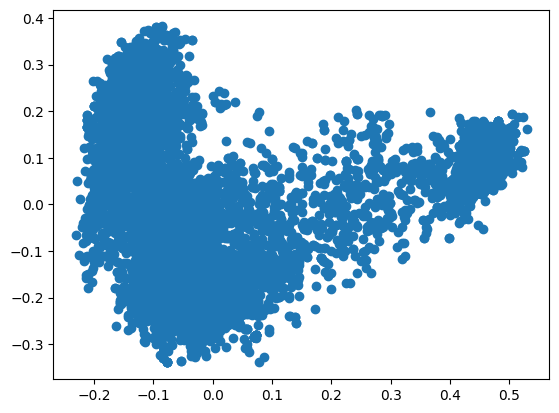

In [56]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Assuming `faiss_index` is your FAISS index object
n = image_index.ntotal  # Number of embeddings
d = image_index.d  # Dimension of embeddings
X = image_index.reconstruct_n(0, n)  # Reconstruct all embeddings

pca = PCA(n_components=2)
X_r = pca.fit_transform(X)

plt.scatter(X_r[:, 0], X_r[:, 1])
plt.show()


## Search indices

In [57]:
def get_item_from_dynamodb(table_name, item_id):
    
    # Get table
    table = dynamodb.Table(table_name)
    
    try:
        # Fetch item by ID
        response = table.get_item(
            Key={
                'id': item_id
            }
        )
    except ClientError as e:
        print(f"An error occurred: {e.response['Error']['Message']}")
        return None
    
    # Return item if found
    return response.get('Item', None)

In [62]:
from collections import defaultdict

def search_image(query_image_url, k=5):
    """
    Search for similar images and texts based on the embedding of a query image.
    
    Parameters:
    - query_image_url (str): The URL of the query image.
    - k (int, optional): The number of top similar items to return. Default is 5.
    
    Returns:
    - list: A list of product IDs for the top k similar items.
    
    """
    query_image_embedding = normalise_embedding(np.array(get_image_embedding(fetch_or_byte(query_image_url), clip_model)))
    
    # Search in Faiss indexes
    image_distances, image_indices = image_index.search(query_image_embedding.reshape(1, -1), k)
    text_distances, text_indices = text_index.search(query_image_embedding.reshape(1, -1), k)
    
    # Retrieve product_ids from indices
    image_product_ids = [global_image_id_to_record[i] for i in image_indices[0]]
    try:
        text_product_ids = [global_text_id_to_record[i] for i in text_indices[0]]
    except Exception as e:
        print((text_distances, text_indices))
        raise e
    
    # Initialize a scoring dictionary
    score_dict = defaultdict(float)
    
    # Weighted scoring
    image_weight = .5
    text_weight = .5
    
    for i, product_id in enumerate(image_product_ids):
        score_dict[product_id] += image_distances[0][i] * image_weight
    
    for i, product_id in enumerate(text_product_ids):
        score_dict[product_id] += text_distances[0][i] * text_weight
    
    # Sort by score and take top k results
    sorted_results = sorted(score_dict.items(), key=lambda x: x[1], reverse=True)
    top_results = [item[0] for item in sorted_results[:k]]
    
    tupresults = []
    
    for product_id in top_results:
        item = get_item_from_dynamodb("ProductTable", product_id)
        print(product_id)
        images=item['image']
        tupresults.append((product_id,images))
        description = item['description']
        print(f"Product ID: {product_id}")
        print(f"Description: {description}")
        print(f"Image URL: {images}")
        print("------")
    
    return tupresults


In [63]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [64]:
from PIL import Image
import matplotlib.pyplot as plt
import requests
from io import BytesIO

def visualize_search_results(query_image, search_results):
    """
    Visualize the search results along with the query image.
    
    Parameters:
    - query_image (str or bytes): The URL or byte content of the query image.
    - search_results (list): A list of product IDs representing the search results.
    - records (list): A list of records containing product information.
    """
    # Display Query Image
    query_img = Image.open(BytesIO(fetch_or_byte(query_image)))
    plt.figure(figsize=(20, 10))
    plt.subplot(1, len(search_results) + 1, 1)
    plt.imshow(query_img)
    plt.title("Query Image")
    plt.axis('off')
    
    # Display Search Results
    for i,result in enumerate(search_results,2):
        response = requests.get(result[1][0])
        img = Image.open(BytesIO(response.content))
        plt.subplot(1, len(search_results) + 1, i)
        plt.imshow(img)
        plt.title(f"ID: {result[0][:8]}")
    
    plt.show()

d12d8e67f9bb082bbef65372a196821b
Product ID: d12d8e67f9bb082bbef65372a196821b
Description: JDX Plain Bed/Sleeping Pillow (Pack of7, White)
                         Price: Rs. 3,370
				
			This is Exclusive comfort cushion with best quality of JDXONLINESALE Color: White, Material: Reliance Fabric Packaging: Plain polybag, Vacuum Packed (Compressed Piece), Washable, Machine wash using a mild detergent. Hang to dry. Re-fluff with hand.
This is Exclusive comfort cushion with best quality of JDXONLINESALE Color: White, Material: Reliance Fabric Packaging: Plain polybag, Vacuum Packed (Compressed Piece), Washable, Machine wash using a mild detergent. Hang to dry. Re-fluff with hand.
Image URL: ['http://img5a.flixcart.com/image/pillow/n/x/w/3drfiljdx-7-41x66-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5j63q4n8eg.jpeg', 'http://img5a.flixcart.com/image/pillow/n/x/w/3drfiljdx-7-41x66-jdx-jdx-premium-3d-reliance-fibre-very-soft-original-imae4a5j63q4n8eg.jpeg', 'http://img6a.flix

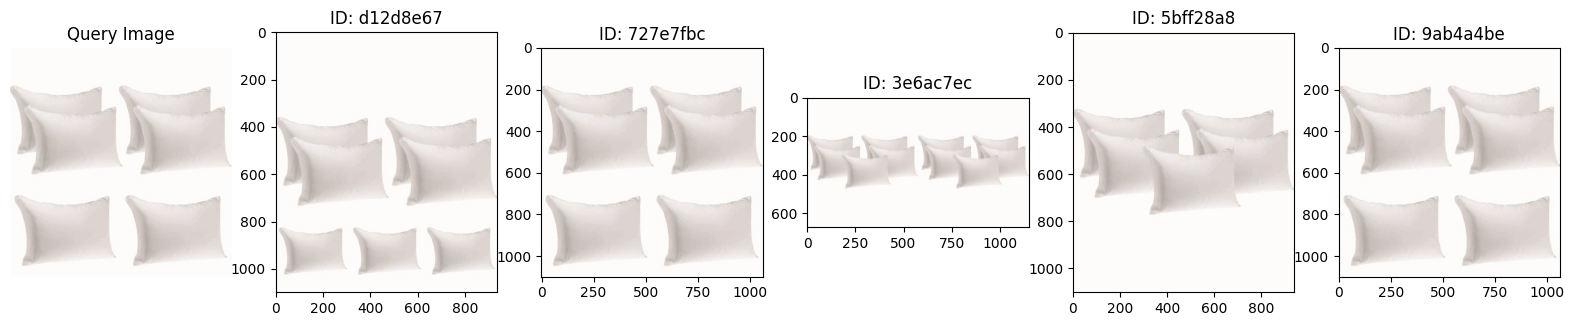

In [65]:

visualize_search_results("http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg", search_image("http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg"))

685ef82735ba9ce3be66dff7f087ef49
Product ID: 685ef82735ba9ce3be66dff7f087ef49
Description: Key Features of Rainfun Solid Men's Raincoat Easy to use Easy to carry,Rainfun Solid Men's Raincoat Price: Rs. 999 Keep yourself ready to face the rain with this full sleeves solid raincoat that is brought to you by RAINFUN. Simple and subtle in design, this raincoat is crafted from superior quality Polyester. This raincoat is sure to enhance your style quotient. It is light in weight and durable and will surely be your best companion in rainy season,Specifications of Rainfun Solid Men's Raincoat Raincoat Details Sleeve Full Sleeve Closure Zip Hooded Yes Reversible Yes Fabric Polyester General Details Pattern Solid Ideal For Men's In the Box 1 Top, 1 Lower Additional Details Style Code Rf_Boss_Black
Image URL: ['http://img5a.flixcart.com/image/raincoat/d/q/f/rf-boss-black-rainfun-xxl-original-imaej4ny6zgsy4f9.jpeg', 'http://img6a.flixcart.com/image/raincoat/d/q/f/rf-boss-black-rainfun-xxl-origina

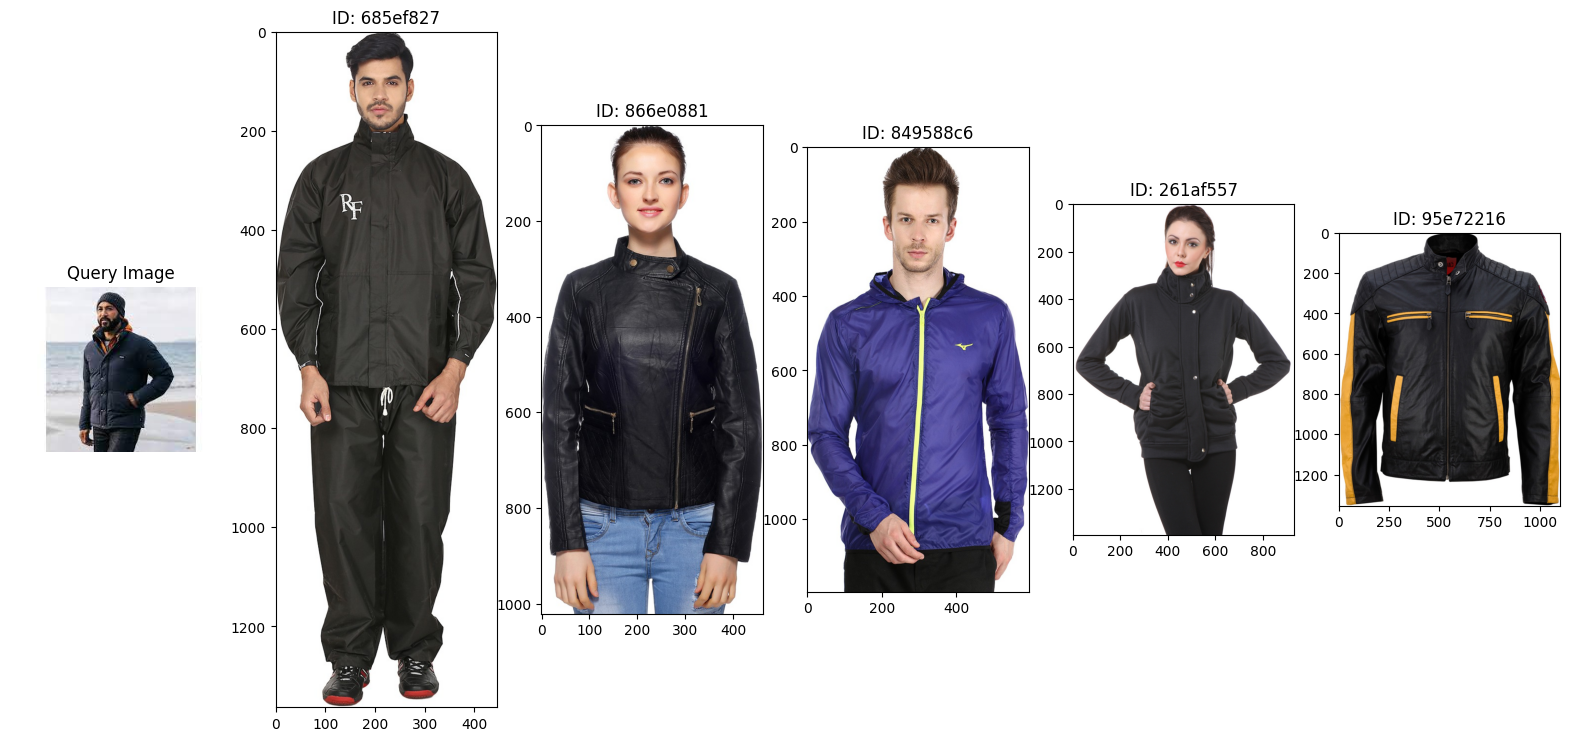

In [66]:
query_image_url ="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSaxZ42Sj1gIFgZHYNuKNnioNKvCQQFZHUdbR18JY6Q76RYFYnPzbOGwqVRI_AuNkX3GBU&usqp=CAU"
visualize_search_results(query_image_url, search_image(query_image_url))

01a9353b9d20f72b12844dae15a8d77a
Product ID: 01a9353b9d20f72b12844dae15a8d77a
Description: Willy Winkies Black Boots
                         Price: Rs. 999
				
			Boots are a classic choice for cold winters or simply for style! These feminine boots are a great choice for any pretty girl. Accentuate your unique style with this chic design!
Boots are a classic choice for cold winters or simply for style! These feminine boots are a great choice for any pretty girl. Accentuate your unique style with this chic design!
Image URL: ['http://img6a.flixcart.com/image/shoe/v/6/h/black-ww-1218-willy-winkies-40-original-imae4j2ym9nwphd5.jpeg', 'http://img6a.flixcart.com/image/shoe/v/6/h/black-ww-1218-willy-winkies-40-original-imae4j2ysyxuj9nx.jpeg', 'http://img5a.flixcart.com/image/shoe/v/6/h/black-ww-1218-willy-winkies-40-original-imae4j2yrpvkgzhw.jpeg', 'http://img5a.flixcart.com/image/shoe/v/6/h/black-ww-1218-willy-winkies-40-original-imae4j2y5pasj8w6.jpeg']
------
02ce7efdeae037f6afdc0e2e89db

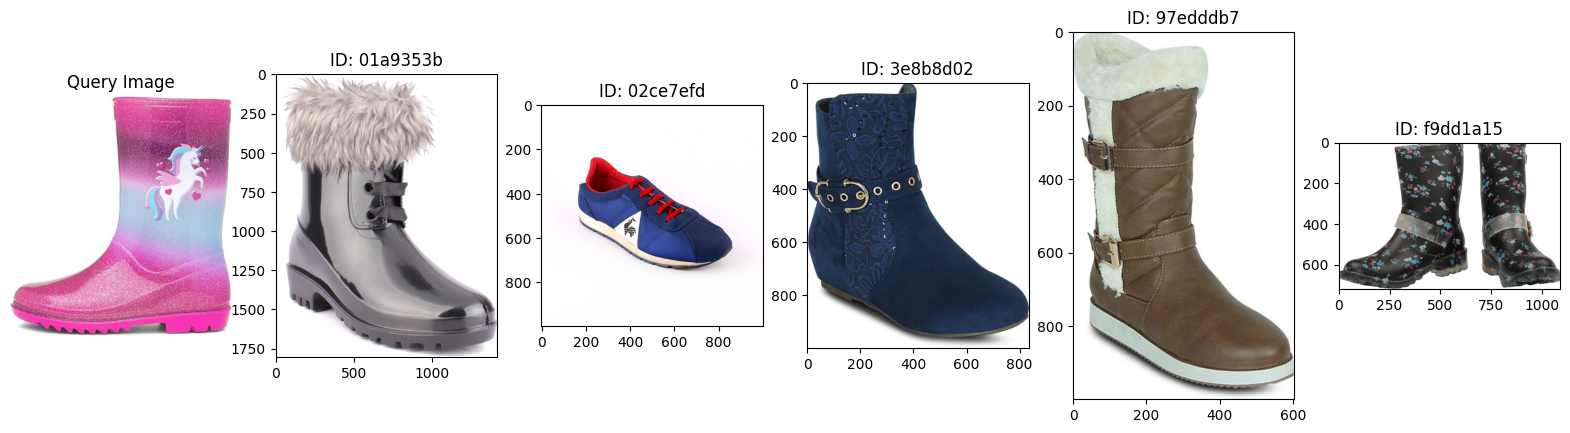

In [67]:
query_image_url ="https://m.media-amazon.com/images/I/71S6Ph8y8GL._AC_UY695_.jpg"
visualize_search_results(query_image_url, search_image(query_image_url))

8dbfb1fb78e6db6bb67a7b9c4649d17f
Product ID: 8dbfb1fb78e6db6bb67a7b9c4649d17f
Description: Kiara Jewellery Sterling Silver Cubic Zirconia Rhodium Ring - Buy Kiara Jewellery Sterling Silver Cubic Zirconia Rhodium Ring only for Rs. 0.0 from Flipkart.com. Only Genuine Products. 30 Day Replacement Guarantee. Free Shipping. Cash On Delivery!
Image URL: ['http://img6a.flixcart.com/image/ring/8/s/f/kir0180-14-kiara-jewellery-ring-original-imadtdy94ujmjrbg.jpeg', 'http://img6a.flixcart.com/image/ring/h/3/c/kir0180-15-kiara-jewellery-ring-original-imaduer3zgbxjb2m.jpeg']
------
3d3281d7c19389253b924ccfb5ea2ef5
Product ID: 3d3281d7c19389253b924ccfb5ea2ef5
Description: Radiant Bay Sumptous Sparkle White Gold Diamond 14 K Ring - Buy Radiant Bay Sumptous Sparkle White Gold Diamond 14 K Ring only for Rs. 20867 from Flipkart.com. Only Genuine Products. 30 Day Replacement Guarantee. Free Shipping. Cash On Delivery!
Image URL: ['http://img6a.flixcart.com/image/ring/m/y/4/rp028660-wg-14k-vvs-gh-7-radian

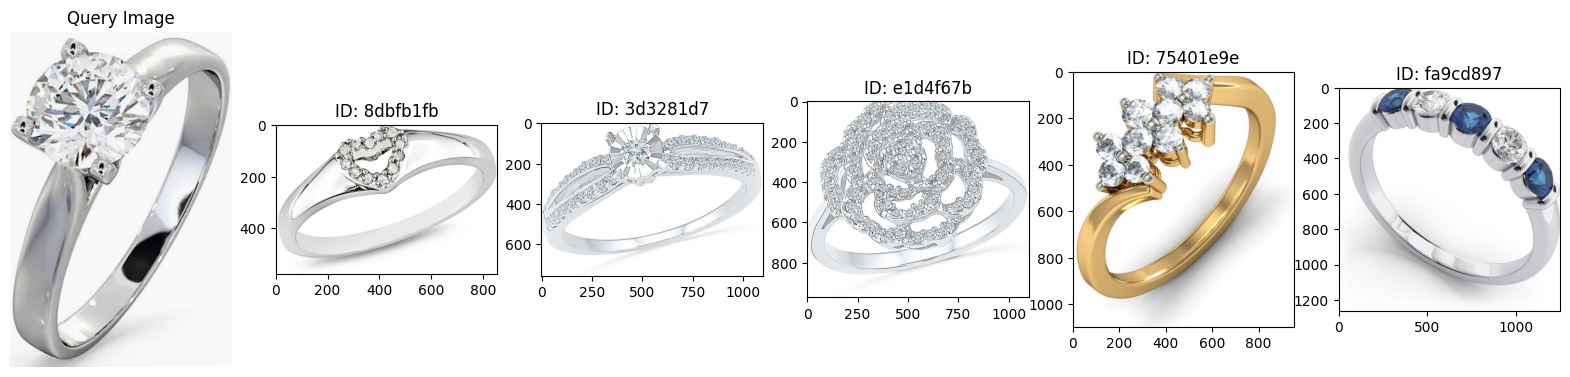

In [68]:
query_image_url = "https://encrypted-tbn3.gstatic.com/shopping?q=tbn:ANd9GcTEJzVGBokOCAhgnFceUDyEUpk9OeO8sh21oCTujgki8RpTDwYnlSeedJ3fTKtFaafg6TYepltQznNXdAItnlV58pHLlEZHo7gRyqsX7raEQmCK3r2jZv1RoYwvUqsP-Y6XDgeqzOY&usqp=CAc"
search_results = search_image(query_image_url)
visualize_search_results(query_image_url, search_results)

4121078e5fa36fe3fedcbbf0950e9851
Product ID: 4121078e5fa36fe3fedcbbf0950e9851
Description: Ozel Studio Casual Full Sleeve Solid Women's Top - Buy Black Ozel Studio Casual Full Sleeve Solid Women's Top For Only Rs. 1425 Online in India. Shop Online For Apparels. Huge Collection of Branded Clothes Only at Flipkart.com
Image URL: ['http://img6a.flixcart.com/image/top/s/r/s/1-1-t-00271-ozel-studio-l-original-imae4w4dgz8yzuvv.jpeg', 'http://img5a.flixcart.com/image/top/s/r/s/1-1-t-00271-ozel-studio-l-original-imae4w4degb3fjsy.jpeg', 'http://img5a.flixcart.com/image/top/s/r/s/1-1-t-00271-ozel-studio-l-original-imae4w4dwnjdvchh.jpeg', 'http://img5a.flixcart.com/image/top/s/r/s/1-1-t-00271-ozel-studio-l-original-imae4w4d6smrqazp.jpeg']
------
585c623e052d18f20c0e9cb9730c0d69
Product ID: 585c623e052d18f20c0e9cb9730c0d69
Description: Shilpkala Casual Short Sleeve Printed Women's Top
                         Price: Rs. 999
				
			Black key printed top has round neck, short sleeves, a sweet heart

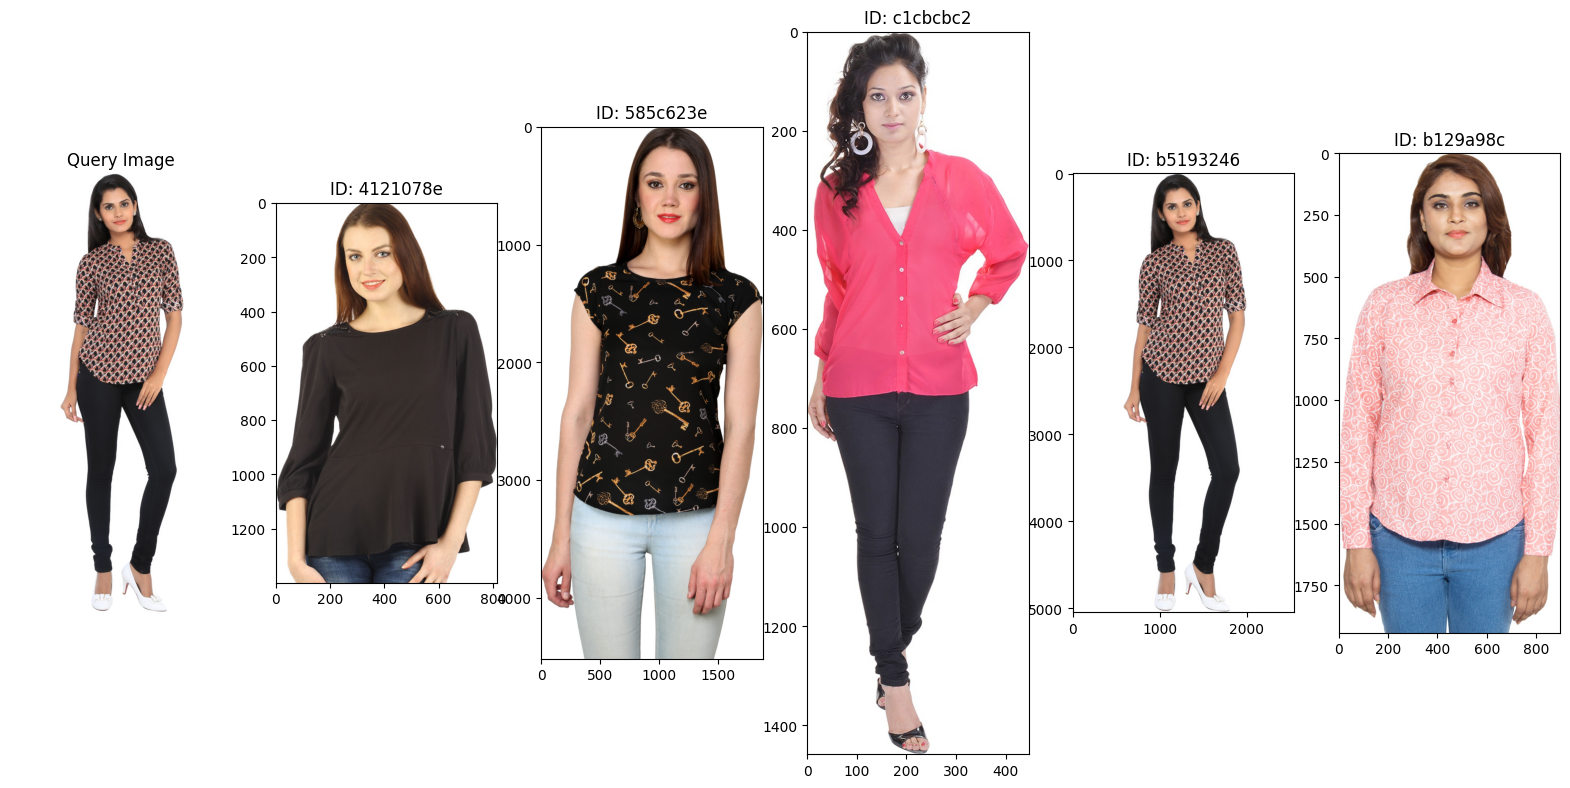

In [69]:
visualize_search_results('http://img5a.flixcart.com/image/top/d/v/u/1-1-mg2171-mangosteen-m-original-imaec88gr9r9erd8.jpeg', search_image('http://img5a.flixcart.com/image/top/d/v/u/1-1-mg2171-mangosteen-m-original-imaec88gr9r9erd8.jpeg'))

In [ ]:
from PIL import Image
from io import BytesIO

def pil_image_to_byte_array(image, format='JPEG'):
    
    if image.mode == 'P':
        image = image.convert('RGB')
    byte_io = BytesIO()
    image.save(byte_io, format=format)
    byte_array = byte_io.getvalue()
    return byte_array


In [ ]:
from PIL import  ImageEnhance
import requests

def process_image(url):
    """
    Process an image from a given URL to generate a list of augmented images.
    
    Parameters:
    - url (str): The URL of the image to be processed.
    
    Returns:
    - list: A list of byte arrays representing the augmented images.
    
    Augmentations Applied:
    1. Rotation: Rotates the original image by 90, 180, and 270 degrees.
    2. Resolution Change: Resizes the original image to resolutions of (200, 200), (400, 400), and (600, 600).
    
    """
    original_img = Image.open(BytesIO(requests.get(url).content))
    augmented_images = []
    enhancer = ImageEnhance.Color(original_img)
    
    # Rotate image
    for angle in [90, 180, 270]:
        img = original_img.rotate(angle)
        augmented_images.append(pil_image_to_byte_array(img))
    
    # Change resolution
    for resolution in [(200, 200), (400, 400), (600, 600)]:
        img = original_img.resize(resolution, Image.ANTIALIAS)
        augmented_images.append(pil_image_to_byte_array(img))
    return augmented_images


In [ ]:
def get_processed_image_embeddings(image_url, clip_model):
    processed_images = process_image(image_url)
    return (get_image_embedding(image_url, clip_model),[get_image_embedding(img_byte_array, clip_model) for img_byte_array in processed_images])


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def cosine_similarity(a, b):
    """
    Compute the cosine similarity between two vectors.
    
    Parameters:
    - a (numpy.ndarray): The first vector.
    - b (numpy.ndarray): The second vector.
    
    Returns:
    - float: The cosine similarity between the two embeddings.
    
    """
    a = np.reshape(a, -1)
    b = np.reshape(b, -1)
    
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot_product / (norm_a * norm_b)


def compare_embeddings(original_embedding, augmented_embeddings):
    """
    Compare the cosine similarities between an original embedding and a list of augmented image embeddings.
    
    Parameters:
    - original_embedding (numpy.ndarray): The original image embedding.
    - augmented_embeddings (list of numpy.ndarray): List of augmented image embeddings.
    
    Returns:
    - None: Displays a heatmap of cosine similarities.
    
    """
    similarities = np.array([cosine_similarity(normalise_embedding(original_embedding), normalise_embedding(aug_emb)) for aug_emb in augmented_embeddings])
    
    # heatmap
    sns.set(font_scale=1.2)
    ax = sns.heatmap([similarities], annot=True, fmt=".3f", cmap="coolwarm", cbar=True, square=True)
    
    # Additional customization
    ax.set_xticklabels([f'Aug_{i+1}' for i in range(len(augmented_embeddings))])
    ax.set_yticklabels(['Original'])
    ax.set_title('Cosine Similarities between Original and Processed Images')
    
    plt.show()



In [ ]:
def compare_results(url):
    visualize_search_results(url, search_image(url), records)
    [visualize_search_results(img, search_image(img), records) for img in process_image(url)]
    

In [ ]:
processed_image_embeddings = get_processed_image_embeddings("https://www.daals.co.uk/cdn/shop/products/Recline_Angle_912c98ba-0643-4d70-b189-a5667e5f8ae4.png?v=1677155030", clip_model)
len(processed_image_embeddings[1])

In [ ]:
compare_embeddings(processed_image_embeddings[0], processed_image_embeddings[1])

In [ ]:
compare_results("https://www.daals.co.uk/cdn/shop/products/Recline_Angle_912c98ba-0643-4d70-b189-a5667e5f8ae4.png?v=1677155030")

## Clean UP

In [ ]:
clip_model.delete_model()
clip_model.delete_endpoint()

In [ ]:
%cd ~/vs

In [ ]:
!rm -r code
!rm -r $model_id

In [ ]:
def delete_table(table_name):
    table = dynamodb.Table(table_name)
    table.delete()

In [ ]:
!rm flipkart_com-ecommerce_sample.json
!rm flipkart_com-ecommerce_sample.csv

In [ ]:
delete_table('ProductTable')
delete_table('CategoryTable')